# Message Intelligence System
### Spam vs Legitimate Message Classification using KNN, SVM and Naive Bayes

### **Objective:** build a Message Intelligence System that classifies 5,200 messages as Legitimate (0) or Spam (1), and compare distance-based (KNN), margin-based (SVM) and probabilistic (Naive Bayes) classifiers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Part A: Probability & Conceptual Foundation

### 1. What is Conditional Probability?
Conditional probability is the probability of an event A happening given that another event B has already happened. It is written P(A | B) = P(A ∩ B) / P(B), where P(B) > 0. It lets us update a probability when new information is known.

### 2. Bayes' Theorem and Its Importance in Classification
**P(Class | Features) = P(Features | Class) × P(Class) / P(Features)**, combining the prior, the likelihood and the evidence into a posterior probability.
It turns "how likely are these features given the class" (easy to estimate from training data) into "how likely is the class given these features" (what we need). The class with the highest posterior is the prediction.

### 3. Assumptions of the Naive Bayes Classifier
1. **Conditional independence:** given the class, all features are independent, so P(x₁, …, xₙ | C) = ∏ P(xᵢ | C).
2. **Feature distribution:** Gaussian Naive Bayes assumes each continuous feature is normally distributed within each class.

These assumptions are rarely fully true, but the classifier often still works well.

### 4. Working Principle

**K-Nearest Neighbors (KNN):** A lazy learner that stores all training data. For a new point it finds the K closest training points (by a distance such as Euclidean) and predicts the majority class among them. Results depend on K and on feature scaling.

**Support Vector Machine (SVM):** It finds the hyperplane that separates the classes with the maximum margin. Only the points closest to the boundary (support vectors) define it. Kernels (linear, polynomial, RBF) allow non-linear boundaries, and C controls the margin versus error trade-off.

### 5. Distance-based vs Probabilistic vs Margin-based Classifiers
- **Distance-based (KNN):** classifies by similarity to nearby points; no training, slow prediction, needs scaling.
- **Probabilistic (Naive Bayes):** classifies by the highest posterior probability; fast, gives probabilities, relies on independence.
- **Margin-based (SVM):** classifies by the maximum-margin boundary; strong on high-dimensional data, needs tuning, harder to interpret with non-linear kernels.

# Part B: Dataset Understanding & Preparation


In [2]:
df = pd.read_excel("Dataset/Message_Intelligence_Dataset_5200.xlsx")

In [3]:
df.head()

,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


In [4]:
df.shape

(5200, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   message_id               5200 non-null   int64         
 1   message_text             5200 non-null   object        
 2   message_length           5200 non-null   int64         
 3   word_count               5200 non-null   int64         
 4   num_urls                 5200 non-null   int64         
 5   num_digits               5200 non-null   int64         
 6   num_special_chars        5200 non-null   int64         
 7   spam_keyword_score       5200 non-null   int64         
 8   legit_keyword_score      5200 non-null   int64         
 9   sender_activity_score    5094 non-null   float64       
 10  sender_account_age_days  5087 non-null   float64       
 11  messages_sent_last_24h   5038 non-null   float64       
 12  timestamp                5200 non-

In [6]:
df.isna().sum()

,0
message_id,0
message_text,0
message_length,0
word_count,0
num_urls,0
num_digits,0
num_special_chars,0
spam_keyword_score,0
legit_keyword_score,0
sender_activity_score,106


In [7]:
df.duplicated().sum()

np.int64(0)

### Identify features and target

In [8]:
df = df.drop(columns=['message_id', 'message_text', 'timestamp'])

X = df.drop(columns=['spam_label'])
y = df['spam_label']

print("X shape:", X.shape, "| y shape:", y.shape)
print("Features:", list(X.columns))
print("Target  : spam_label (0 = Legitimate, 1 = Spam)")

X shape: (5200, 12) | y shape: (5200,)
Features: ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
Target  : spam_label (0 = Legitimate, 1 = Spam)


### Preprocessing

In [9]:
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)
X_imputed = pd.DataFrame(X_imputed, columns=X.columns)

In [10]:
X_imputed.isna().sum()

,0
message_length,0
word_count,0
num_urls,0
num_digits,0
num_special_chars,0
spam_keyword_score,0
legit_keyword_score,0
sender_activity_score,0
sender_account_age_days,0
messages_sent_last_24h,0


In [11]:
df['spam_label'].value_counts()

,count
spam_label,
0,4227
1,973


### Train/test split

In [12]:
X_train , X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=50)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (4160, 12)
X_test shape: (1040, 12)


In [13]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)


# Part C: Baseline Model – K-Nearest Neighbors

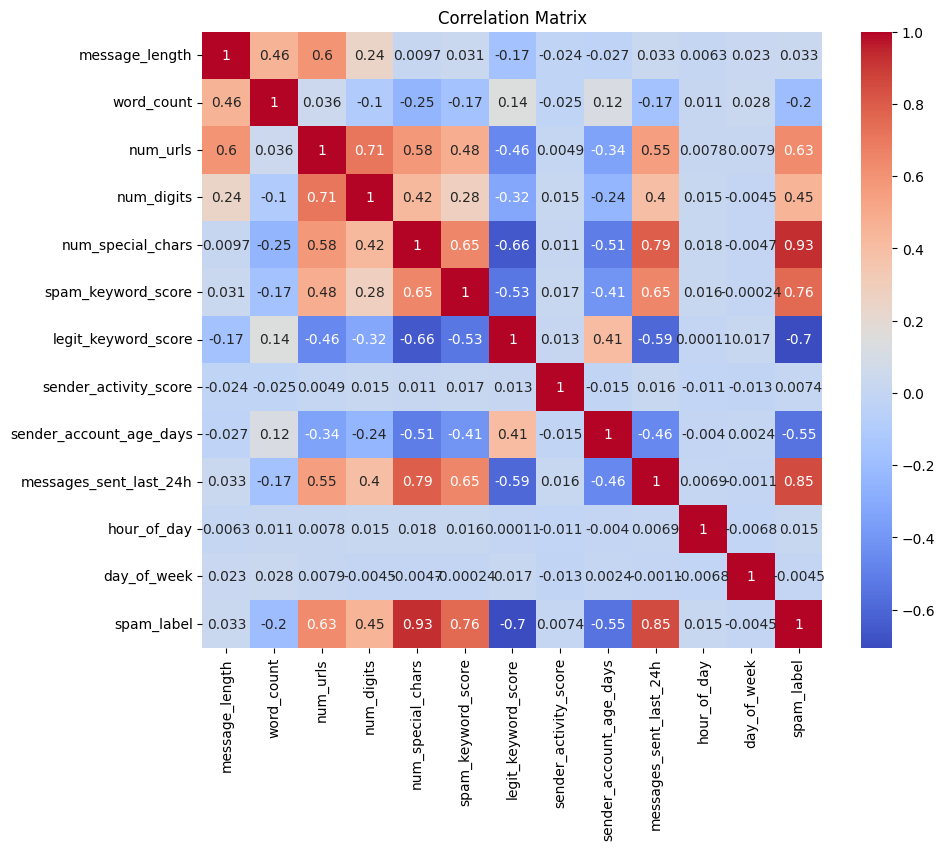

In [14]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.savefig('correlation_matrix.png', dpi=300)
plt.show()

### KNN

In [15]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

In [16]:
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1 Score:", f1_score(y_test, knn_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


### Different K

In [17]:
k = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
result = []

for i in k:
  knn_model = KNeighborsClassifier(n_neighbors=i)
  knn_model.fit(X_train_scaled, y_train)
  knn_pred = knn_model.predict(X_test_scaled)
  result.append({'k': i, 'accuracy': accuracy_score(y_test, knn_pred),
                 'Precision': precision_score(y_test, knn_pred),
                 'Recall': recall_score(y_test, knn_pred),
                 'f1-score': f1_score(y_test, knn_pred)
                 })

result = pd.DataFrame(result)
result

,k,accuracy,Precision,Recall,f1-score
0,1,1.000000,1.0,1.000000,1.000000
1,3,1.000000,1.0,1.000000,1.000000
2,5,1.000000,1.0,1.000000,1.000000
3,7,1.000000,1.0,1.000000,1.000000
4,9,1.000000,1.0,1.000000,1.000000
5,11,1.000000,1.0,1.000000,1.000000
6,13,1.000000,1.0,1.000000,1.000000
7,15,1.000000,1.0,1.000000,1.000000
8,17,0.999038,1.0,0.994681,0.997333
9,19,0.999038,1.0,0.994681,0.997333


### Distance metrics

In [18]:
distances = ['euclidean', 'manhattan', 'minkowski']
result = []

for i in distances:
  knn_model = KNeighborsClassifier(n_neighbors=5, metric=i)
  knn_model.fit(X_train_scaled, y_train)
  knn_pred = knn_model.predict(X_test_scaled)
  result.append({'distance': i, 'accuracy': accuracy_score(y_test, knn_pred),
                 'Precision': precision_score(y_test, knn_pred),
                 'Recall': recall_score(y_test, knn_pred),
                 'f1-score': f1_score(y_test, knn_pred)
                 })

result = pd.DataFrame(result)
result

,distance,accuracy,Precision,Recall,f1-score
0,euclidean,1.0,1.0,1.0,1.0
1,manhattan,1.0,1.0,1.0,1.0
2,minkowski,1.0,1.0,1.0,1.0


In [19]:
knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_scaled, y_train)
y_pred_final = knn_final.predict(X_test_scaled)

misclassified_mask = (y_pred_final != y_test.values)
misclassified_indices = X_test.index[misclassified_mask]

print("Number of Misclassified Messages :", len(misclassified_indices))

if len(misclassified_indices) > 0:
    sample_idx = misclassified_indices[0]
    print("\nExample Misclassified Message :")
    print(df.loc[sample_idx, ['message_text', 'spam_label']])
    print("Predicted as :", y_pred_final[list(X_test.index).index(sample_idx)])
else:
    print("No misclassifications found on the test set.")

Number of Misclassified Messages : 0
No misclassifications found on the test set.


# Part D: Support Vector Machine Classifier


## SVC with linear kernel

In [20]:
svc_linear = SVC(kernel='linear')
svc_linear.fit(X_train_scaled, y_train)
svc_pred = svc_linear.predict(X_test_scaled)

## SVC with polynomial kernel

In [21]:
svc_poly = SVC(kernel='poly')
svc_poly.fit(X_train_scaled, y_train)
svc_pred = svc_poly.predict(X_test_scaled)

## SVC with rbf kernel

In [22]:
svc_rbf = SVC(kernel='rbf')
svc_rbf.fit(X_train_scaled, y_train)
svc_pred = svc_rbf.predict(X_test_scaled)

In [23]:
svm_results = pd.DataFrame({
    'Model': ['Linear', 'Polynomial', 'RBF'],
    'Accuracy': [accuracy_score(y_test, svc_linear.predict(X_test_scaled)), accuracy_score(y_test, svc_poly.predict(X_test_scaled)), accuracy_score(y_test, svc_rbf.predict(X_test_scaled))],
    'Precision': [precision_score(y_test, svc_linear.predict(X_test_scaled)), precision_score(y_test, svc_poly.predict(X_test_scaled)), precision_score(y_test, svc_rbf.predict(X_test_scaled))],
    'Recall': [recall_score(y_test, svc_linear.predict(X_test_scaled)), recall_score(y_test, svc_poly.predict(X_test_scaled)), recall_score(y_test, svc_rbf.predict(X_test_scaled))],
    'F1 Score': [f1_score(y_test, svc_linear.predict(X_test_scaled)), f1_score(y_test, svc_poly.predict(X_test_scaled)), f1_score(y_test, svc_rbf.predict(X_test_scaled))]
})

svm_results


,Model,Accuracy,Precision,Recall,F1 Score
0,Linear,1.0,1.0,1.0,1.0
1,Polynomial,1.0,1.0,1.0,1.0
2,RBF,1.0,1.0,1.0,1.0


In [24]:
print("Number of Support Vectors per Class (Linear Kernel) :", svc_linear.n_support_)
print("Total Support Vectors :", sum(svc_linear.n_support_))
print("Total Training Samples :", len(X_train_scaled))
print("Support Vector Percentage :", round(sum(svc_linear.n_support_) / len(X_train_scaled) * 100, 2), "%")

Number of Support Vectors per Class (Linear Kernel) : [8 5]
Total Support Vectors : 13
Total Training Samples : 4160
Support Vector Percentage : 0.31 %


## Comparision

In [25]:
knn_vs_svc = pd.DataFrame({
    'Model': ['KNN', 'Linear SVC', 'Polynomial SVC', 'RBF SVC'],
    'Accuracy': [accuracy_score(y_test, knn_pred), accuracy_score(y_test, svc_linear.predict(X_test_scaled)), accuracy_score(y_test, svc_poly.predict(X_test_scaled)), accuracy_score(y_test, svc_rbf.predict(X_test_scaled))],
    'Precision': [precision_score(y_test, knn_pred), precision_score(y_test, svc_linear.predict(X_test_scaled)), precision_score(y_test, svc_poly.predict(X_test_scaled)), precision_score(y_test, svc_rbf.predict(X_test_scaled))],
    'Recall': [recall_score(y_test, knn_pred), recall_score(y_test, svc_linear.predict(X_test_scaled)), recall_score(y_test, svc_poly.predict(X_test_scaled)), recall_score(y_test, svc_rbf.predict(X_test_scaled))],
    'F1 Score': [f1_score(y_test, knn_pred), f1_score(y_test, svc_linear.predict(X_test_scaled)), f1_score(y_test, svc_poly.predict(X_test_scaled)), f1_score(y_test, svc_rbf.predict(X_test_scaled))]
})

knn_vs_svc

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,1.0,1.0,1.0,1.0
1,Linear SVC,1.0,1.0,1.0,1.0
2,Polynomial SVC,1.0,1.0,1.0,1.0
3,RBF SVC,1.0,1.0,1.0,1.0


# Part E: Naive Bayes Classifier & Probability

In [26]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
nb_pred = nb_model.predict(X_test_scaled)

In [27]:
print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1 Score:", f1_score(y_test, nb_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [28]:
print("Confusion Matrix :")
print(confusion_matrix(y_test, nb_pred))

Confusion Matrix :
[[852   0]
 [  0 188]]


In [29]:
# Yes/no flags (derived columns, not in the original dataset)
df['has_url'] = (df['num_urls'] >= 1).astype(int)
df['has_spam_kw'] = (df['spam_keyword_score'] > 0).astype(int)
df['has_digits'] = (df['num_digits'] > 0).astype(int)
flags = ['has_url', 'has_spam_kw', 'has_digits']

# Four sample messages (row numbers in df) with different flag patterns
sample_rows = {
    'Sample 1: spam, keyword only': 5,
    'Sample 2: legit, no signals': 1,
    'Sample 3: legit, URL + digits': 0,
    'Sample 4: spam, URL + keyword + digits': 17
}

df.loc[list(sample_rows.values()), flags + ['spam_label']]

,has_url,has_spam_kw,has_digits,spam_label
5,0,1,0,1
1,0,0,0,0
0,1,0,1,0
17,1,1,1,1


In [30]:
# Conditional probabilities: P(flag = 1 | Spam) and P(flag = 1 | Legitimate)
spam_df = df[df['spam_label'] == 1]
legit_df = df[df['spam_label'] == 0]

p1_spam = spam_df[flags].mean()
p1_legit = legit_df[flags].mean()

pd.DataFrame({'P(flag=1 | Spam)': p1_spam, 'P(flag=1 | Legitimate)': p1_legit}).round(4)

,P(flag=1 | Spam),P(flag=1 | Legitimate)
has_url,0.7390,0.0840
has_spam_kw,0.7657,0.0000
has_digits,0.7821,0.2673


### Apply Bayes' Theorem to Compute Class Probability

**P(Spam | x) = P(x | Spam) × P(Spam) / P(x)**, where P(x) = P(x | Spam) × P(Spam) + P(x | Legitimate) × P(Legitimate)

In [31]:
p_spam = df['spam_label'].mean()
p_legit = 1 - p_spam

# Likelihoods
p_url_given_spam = df[df['spam_label'] == 1]['has_url'].mean()
p_url_given_legit = df[df['spam_label'] == 0]['has_url'].mean()

# Evidence
p_url = df['has_url'].mean()

print("P(Spam)                :", round(p_spam, 4))
print("P(HasURL | Spam)       :", round(p_url_given_spam, 4))
print("P(HasURL | Legitimate) :", round(p_url_given_legit, 4))
print("P(HasURL)              :", round(p_url, 4))

P(Spam)                : 0.1871
P(HasURL | Spam)       : 0.739
P(HasURL | Legitimate) : 0.084
P(HasURL)              : 0.2065


In [32]:
# Bayes' Theorem:
# P(Class | HasURL) = [ P(HasURL | Class) * P(Class) ] / P(HasURL)

p_spam_given_url = (p_url_given_spam * p_spam) / p_url
p_legit_given_url = (p_url_given_legit * p_legit) / p_url

print("P(Spam | HasURL)       =", round(p_spam_given_url, 4))
print("P(Legitimate | HasURL) =", round(p_legit_given_url, 4))
print("Sum (must be 1)        =", round(p_spam_given_url + p_legit_given_url, 4))

print("\nInterpretation: If a message contains a URL, there is about",
      round(p_spam_given_url * 100, 1), "% probability it is Spam and",
      round(p_legit_given_url * 100, 1), "% probability it is Legitimate.")

P(Spam | HasURL)       = 0.6695
P(Legitimate | HasURL) = 0.3305
Sum (must be 1)        = 1.0

Interpretation: If a message contains a URL, there is about 66.9 % probability it is Spam and 33.1 % probability it is Legitimate.


In [33]:
# Theoretical probability for a message with NO URL (same Bayes' theorem)
p_spam_given_nourl = ((1 - p_url_given_spam) * p_spam) / (1 - p_url)

# Naive Bayes model trained on the same feature (has_url)
nb_url = BernoulliNB(alpha=1e-10)
nb_url.fit(df[['has_url']], df['spam_label'])

# Model probabilities for a message WITH a URL (1) and WITHOUT a URL (0)
model_proba = nb_url.predict_proba(pd.DataFrame({'has_url': [1, 0]}))

comparison = pd.DataFrame({
    'Case': ['HasURL = 1', 'HasURL = 0'],
    'Theoretical P(Spam)': [p_spam_given_url, p_spam_given_nourl],
    'Model P(Spam)': model_proba[:, 1]
})
comparison['Difference'] = (comparison['Theoretical P(Spam)'] - comparison['Model P(Spam)']).abs()
comparison['Theoretical Prediction'] = (comparison['Theoretical P(Spam)'] > 0.5).map({True: 'Spam', False: 'Legitimate'})
comparison['Model Prediction'] = (comparison['Model P(Spam)'] > 0.5).map({True: 'Spam', False: 'Legitimate'})

comparison.round(4)

,Case,Theoretical P(Spam),Model P(Spam),Difference,Theoretical Prediction,Model Prediction
0,HasURL = 1,0.6695,0.6695,0.0,Spam,Spam
1,HasURL = 0,0.0616,0.0616,0.0,Legitimate,Legitimate


# Part F: Model Comparison & Evaluation



In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=50)
cv_models = {'KNN': KNeighborsClassifier(5), 'Linear SVC': SVC(kernel='linear'),
             'Polynomial SVC': SVC(kernel='poly'), 'RBF SVC': SVC(kernel='rbf'), 'Naive Bayes': GaussianNB()}
cv_rows = []
for n, m in cv_models.items():
    pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', m)])
    s = cross_val_score(pipe, X, y, cv=cv, scoring='f1')
    cv_rows.append({'Model': n, 'Mean F1': s.mean(), 'Std': s.std()})
pd.DataFrame(cv_rows).round(4)

,Model,Mean F1,Std
0,KNN,0.9995,0.001
1,Linear SVC,1.0000,0.000
2,Polynomial SVC,1.0000,0.000
3,RBF SVC,1.0000,0.000
4,Naive Bayes,1.0000,0.000


In [35]:
models = {
    'KNN': knn_final,
    'Linear SVC': svc_linear,
    'Polynomial SVC': svc_poly,
    'RBF SVC': svc_rbf,
    'Naive Bayes': nb_model
}

rows = []
for name, model in models.items():
    pred = model.predict(X_test_scaled)

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([name,
                 accuracy_score(y_test, pred),
                 precision_score(y_test, pred),
                 recall_score(y_test, pred),
                 f1_score(y_test, pred),
                 tn, fp, fn, tp,
                 ])

final_results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score',
                                            'TN', 'FP', 'FN', 'TP'])
final_results

,Model,Accuracy,Precision,Recall,F1 Score,TN,FP,FN,TP
0,KNN,1.0,1.0,1.0,1.0,852,0,0,188
1,Linear SVC,1.0,1.0,1.0,1.0,852,0,0,188
2,Polynomial SVC,1.0,1.0,1.0,1.0,852,0,0,188
3,RBF SVC,1.0,1.0,1.0,1.0,852,0,0,188
4,Naive Bayes,1.0,1.0,1.0,1.0,852,0,0,188


**Interpretation:** All five models reach Accuracy, Precision, Recall and F1 of 1.0 on the test set (852 legitimate and 188 spam messages): no false positives and no false negatives.

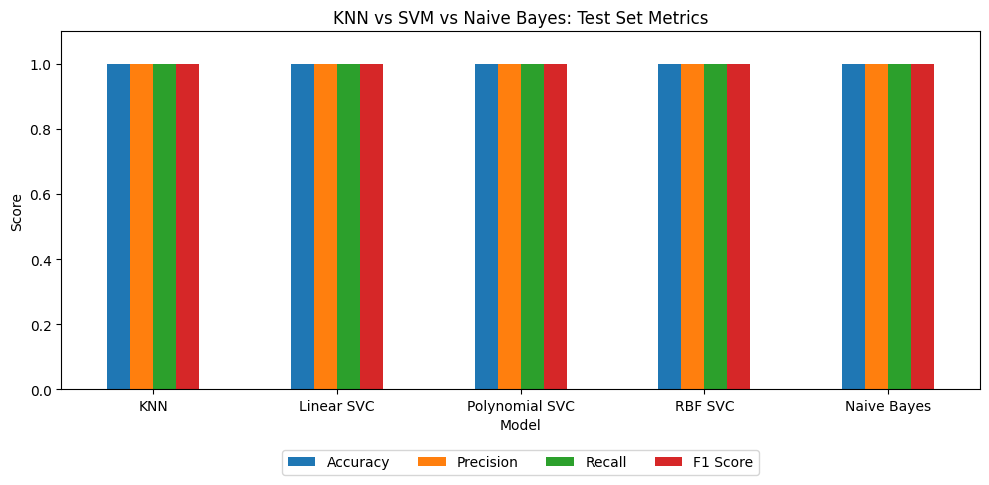

In [36]:
final_results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar', figsize=(10, 5), ylim=(0, 1.1))

plt.title('KNN vs SVM vs Naive Bayes: Test Set Metrics')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300)
plt.show()

In [37]:
best_precision = final_results['Precision'].max()
best_recall = final_results['Recall'].max()

print("Highest Precision :", best_precision, "->", list(final_results[final_results['Precision'] == best_precision]['Model']))
print("Highest Recall    :", best_recall, "->", list(final_results[final_results['Recall'] == best_recall]['Model']))

Highest Precision : 1.0 -> ['KNN', 'Linear SVC', 'Polynomial SVC', 'RBF SVC', 'Naive Bayes']
Highest Recall    : 1.0 -> ['KNN', 'Linear SVC', 'Polynomial SVC', 'RBF SVC', 'Naive Bayes']


# Part G: Final Analysis & Reporting



- **Data:** 5,200 messages, 12 numerical features, 18.7% spam (973) and 81.3% legitimate (4,227). The test set has 1,040 messages (852 legitimate, 188 spam).
- **Performance:** on the test set, KNN (K = 5), Linear SVC, Polynomial SVC, RBF SVC and Gaussian Naive Bayes all score Accuracy, Precision, Recall and F1 of 1.0. In 5-fold cross-validation, the SVM models and Naive Bayes keep F1 = 1.0 and KNN scores 0.9995. No model is meaningfully better on accuracy.
- **Why:** the classes are almost perfectly separable. Every spam message contains at least one special character and no legitimate message contains any, so a single feature separates the classes.
- **Consequence:** the choice of model must be made on interpretability, speed, robustness and business risk, not on accuracy.

## Strengths and Weaknesses of Each Classifier

| Classifier | Strengths | Weaknesses |
|---|---|---|
| **KNN** | No training phase. Simple. Explains a decision by showing the most similar known messages. Adapts to local patterns. | Slow prediction (compares each message with all 4,160 stored messages). Needs scaling. Sensitive to K and to noise. Memory heavy. |
| **SVM** (Linear, Polynomial, RBF) | Maximum-margin boundary generalises well. Handles correlated features. Uses very few training points (support vectors). Linear kernel is fast and gives one weight per feature. | Needs scaling and tuning (C, kernel, gamma). No built-in probabilities. Training slows on large data. Polynomial and RBF kernels are hard to interpret. |
| **Naive Bayes** (Gaussian) | Very fast to train and predict. Gives explicit class probabilities. Each feature's contribution can be shown. Needs little data. Hand calculation matches the model exactly. | Assumes features are independent given the class. Probabilities are overconfident. Zero-frequency problem. Gaussian assumption is wrong for count features. |

## Impact of Probability Assumptions in Naive Bayes

1. **Conditional independence.** Naive Bayes multiplies feature likelihoods as if features were unrelated. Inside each class, content features are correlated: `message_length` and `num_urls` (r = 0.77 legitimate, 0.72 spam), `num_urls` and `num_digits` (r = 0.59 legitimate, 0.68 spam). A URL adds characters and digits, so the same evidence is counted more than once. In the hand calculation (Task 17-19 cells in Part E), a legitimate message with a URL and digits received P(Spam | x) = 0.5813 and was wrongly predicted as spam, both by hand and by the model. The error comes from the assumption, not from the code.
2. **Overconfident probabilities.** Every test prediction has P(Spam) below 0.01 or above 0.99. The class decision is reliable, but the probabilities are not calibrated and should not be used as risk scores.
3. **Zero-frequency problem.** No legitimate message contains a spam keyword or a special character, so P(feature | Legitimate) = 0 for them. Without smoothing, any message with such a feature gets P(Spam) = 1.0 exactly. Laplace smoothing (`alpha`) or variance smoothing (`var_smoothing`) is required.
4. **Gaussian assumption.** `num_urls` (0 or 1) and `num_special_chars` (0 to 2) are not normally distributed. The model still classifies correctly because its decision is dominated by a few very strong features.
5. **Classification is more forgiving than probability.** Naive Bayes needs only P(Spam | x) > P(Legitimate | x) to be correct, so wrong probabilities can still give the right class. That explains 100% test accuracy despite the violated assumptions.

## Trade-offs Between Interpretability and Performance

| Model | Interpretability | How a decision is explained |
|---|---|---|
| Naive Bayes | High | Prior, per-feature likelihoods and posterior can be shown step by step (Task 17-19 cells in Part E). |
| Linear SVC | High | One weight per feature shows which features push a message towards spam. |
| KNN | Medium | Shows the most similar known messages, but there is no global rule. |
| Polynomial / RBF SVC | Low | Decision happens in a transformed feature space. Only support vectors are available. |

Performance is identical here, so the more complex models (Polynomial and RBF SVC) give up interpretability and gain nothing. On harder real-world data, complex models may win on accuracy, and the trade-off would become real. Where blocked messages must be explained to users or auditors, a linear SVC or Naive Bayes model is preferable.

## Business Recommendation for Real-World Deployment

1. **Primary model: Linear SVC.** It matches every other model on accuracy, predicts very fast, needs no kernel tuning, is not affected by the independence assumption, and its feature weights explain decisions. Its signed distance from the decision boundary can serve as a spam score.
2. **Secondary model: Naive Bayes** for explanation and cross-checking only, not for probability reporting.
3. **Set the threshold by business cost.** A false positive blocks a legitimate message and harms user trust. A false negative lets spam through and harms security. Agree the cost ratio with stakeholders, start with a high-precision threshold, and send borderline messages (score near the boundary) to **human review** instead of auto-blocking. A URL alone is not enough evidence: about 33% of messages with a URL are legitimate.
4. **Validate before launch.** Test on fresh, labelled production messages. A 100% result and a single perfectly separating feature mean this dataset is probably easier than real traffic.
5. **Expect spammers to adapt.** Removing special characters or URLs would break the dominant signals. Monitor precision and recall regularly, watch for feature drift, and retrain on new labelled data.
6. **Deploy one pipeline.** Save the imputer, scaler and model together (for example with `joblib`) so the Streamlit app and production use identical preprocessing.

# Final Conclusion

**Findings**
- **Data and preparation:** 12 numeric features, 18.7% spam. Missing values in three sender-behaviour columns were filled with the median, and features were standardised before KNN, SVM and Naive Bayes.
- **KNN:** scores 1.0 on all metrics for K = 1 to 15 with every distance metric tested (Euclidean, Manhattan, Minkowski). At K = 17 and K = 19, recall drops slightly (0.9947) and accuracy to 0.999, because a larger K lets legitimate neighbours outvote a few spam messages.
- **SVM:** Linear, Polynomial and RBF kernels all score 1.0. The linear SVM needs only 13 of 4,160 training points (0.31%) as support vectors, which shows how cleanly the two classes separate.
- **Naive Bayes:** Gaussian Naive Bayes also scores 1.0 (852 legitimate and 188 spam test messages classified correctly, no false positives or negatives). The hand-calculated Bayes posterior for a message with a URL (P(Spam | URL) = 0.6695) matches the model output exactly, so Naive Bayes is Bayes' theorem combined with the independence assumption.
- **Cross-validation:** in 5-fold stratified cross-validation, Linear SVC, Polynomial SVC, RBF SVC and Naive Bayes keep F1 = 1.0, and KNN scores 0.9995. The ranking holds beyond the single split.

**Comparison:** KNN, SVM and Naive Bayes tie on the test set for both highest precision and highest recall. Accuracy therefore cannot decide between them. KNN is the only model that loses recall (at large K and in cross-validation).

**Why the scores are perfect:** the classes are almost perfectly separable, so even simple models succeed. A single strong signal dominates the decision, and this dataset is probably easier than real traffic.

**Recommendation:** use **Linear SVC** as the primary model. It matches every other model, predicts quickly, needs no kernel tuning, and its feature weights explain each decision. Keep Naive Bayes as a secondary model for explanation and cross-checking, not for reporting probabilities. Choose the decision threshold by business cost, send borderline messages to human review, and validate on fresh labelled messages before launch. Monitor precision and recall regularly and retrain as spam patterns change.